# 02 · Baseline — CNN desde cero (Keras, CPU)

**Objetivo:** tener un punto de referencia simple antes de usar transfer learning. El modelo del notebook 03 se compara contra los resultados de este.

**Decisiones (tomadas a partir del EDA):**
- Métrica principal: **F1 macro**, porque hay un desbalance de ~36x entre clases.
- Se mantiene `Background_without_leaves` como clase y se reportan también las métricas sin ella.
- Se compara entrenar **con y sin `class_weight`** (pesos que dan más importancia a las clases con menos imágenes), con una corrida para cada caso.
- Imágenes reducidas a 128x128 y entrenamiento con el 25 % de train, para poder entrenar en CPU en un tiempo razonable.

## 1. Setup

Se importan las librerías, se fija la semilla (42) para que los resultados sean reproducibles y se carga la función de datos de `src/data.py`. Si TensorFlow informa que no usa GPU, es lo esperado: todo el entrenamiento corre en CPU.

In [1]:
import os
import sys
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from src.data import load_splits, to_arrays

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams["figure.dpi"] = 110
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Configuración del experimento

- `IMG_SIZE`, `BATCH` y `EPOCHS`: tamaño de entrada (128x128, más chico que el del transfer learning para ahorrar cómputo), tamaño del lote y máximo de épocas.
- `USE_SUBSET` y `SUBSET_FRACTION`: con `USE_SUBSET=True` se entrena con una fracción estratificada de train (25 %, unas 9.700 imágenes). Es la configuración de los resultados reportados y la que usa el notebook 03 para comparar.
- `USE_CLASS_WEIGHT`: activa o no los pesos de clase balanceados. Se hizo una corrida con cada valor.
- `EXP_NAME`: nombre del experimento; define los archivos que se guardan en `models/` y `reports/`.

In [2]:
IMG_SIZE = (128, 128)      # (ancho, alto)
BATCH = 32
EPOCHS = 15

USE_SUBSET = True          # True: usa una fracción estratificada de train
SUBSET_FRACTION = 0.25
USE_CLASS_WEIGHT = False   # True: aplica pesos de clase balanceados

EXP_NAME = (
    f"baseline_{'cw' if USE_CLASS_WEIGHT else 'nocw'}_{IMG_SIZE[0]}"
    + ("_subset" if USE_SUBSET else "_full")
)
print("Experimento:", EXP_NAME)

Experimento: baseline_nocw_128_subset


## 3. Datos

Se cargan los splits del notebook 01 y las imágenes se convierten una sola vez en arrays de 128x128, que se guardan en `data/cache/` y se leen desde disco en las ejecuciones siguientes. Después, si `USE_SUBSET=True`, se toma una muestra estratificada del 25 % de train (9.703 imágenes) que mantiene la proporción de cada clase.

In [3]:
train, val, test = load_splits()

label_feat = train.features["label"]
id2name = dict(enumerate(label_feat.names))
n_classes = len(id2name)
bg_id = [k for k, v in id2name.items() if v.startswith("Background")][0]
print("Clases:", n_classes, "| id de la clase fondo:", bg_id)

AVISO: el dataset no trae leaf_id; se usa un split estratificado por clase. Puede haber fuga entre imágenes de una misma hoja, por lo que las métricas pueden ser algo optimistas.
Clases: 39 | id de la clase fondo: 4


In [4]:
t0 = time.time()
X_train, y_train = to_arrays(train, IMG_SIZE, name="train")
X_val, y_val = to_arrays(val, IMG_SIZE, name="val")
X_test, y_test = to_arrays(test, IMG_SIZE, name="test")
print(f"Listo en {time.time() - t0:.0f} s")
print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

[cache] train_38812_128x128.npz
[cache] val_8317_128x128.npz
[cache] test_8318_128x128.npz
Listo en 7 s
train: (38812, 128, 128, 3) | val: (8317, 128, 128, 3) | test: (8318, 128, 128, 3)


In [5]:
if USE_SUBSET:
    idx = np.arange(len(y_train))
    keep, _ = train_test_split(
        idx, train_size=SUBSET_FRACTION, stratify=y_train, random_state=SEED
    )
    X_train, y_train = X_train[keep], y_train[keep]
    print("Train reducido a:", X_train.shape)

Train reducido a: (9703, 128, 128, 3)


## 4. Pesos de clase

Los pesos `balanced` de scikit-learn son inversamente proporcionales a la frecuencia de cada clase: las clases con pocas imágenes pesan más en la función de pérdida (aquí, entre 0,26 y 9,57). Se aplican solo si `USE_CLASS_WEIGHT=True`.

In [6]:
classes = np.arange(n_classes)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}

print(f"Pesos: min={min(weights):.2f}  max={max(weights):.2f}")
cw = class_weight if USE_CLASS_WEIGHT else None
print("Usando class_weight:", USE_CLASS_WEIGHT)

Pesos: min=0.26  max=9.57
Usando class_weight: False


## 5. Modelo

CNN chica de 4 bloques (Conv → BatchNorm → ReLU → MaxPool, con 16, 32, 64 y 128 filtros) seguida de `GlobalAveragePooling`, dropout de 0,3 y una capa densa de 39 salidas. Tiene 103.191 parámetros y está pensada para ser rápida en CPU. El augmentation (flip horizontal y vertical, rotación leve y zoom) va dentro del modelo y solo se aplica al entrenar.

In [7]:
def build_baseline(input_shape, n_classes):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)

    # Augmentation (solo activo en entrenamiento)
    x = layers.RandomFlip("horizontal_and_vertical")(x)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)

    for filters in (16, 32, 64, 128):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn")

model = build_baseline((IMG_SIZE[1], IMG_SIZE[0], 3), n_classes)
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 103,191 (403.09 KB)

 Trainable params: 102,711 (401.21 KB)

 Non-trainable params: 480 (1.88 KB)

## 6. Entrenamiento

Se usa el optimizador Adam (tasa de aprendizaje inicial de 1e-3) y tres callbacks: `EarlyStopping` (detiene el entrenamiento si `val_loss` no mejora en 4 épocas), `ReduceLROnPlateau` (reduce a la mitad la tasa de aprendizaje si no mejora en 2 épocas) y `ModelCheckpoint` (guarda en `models/` la mejor versión según `val_loss`). Con el 25 % de train, cada época tarda alrededor de 75 segundos y el entrenamiento completo, entre 18 y 20 minutos. En las primeras épocas la validación es inestable (la `val_accuracy` es de 0,07 en la época 1 y de 0,56 en la 2) y mejora a medida que avanza el entrenamiento.

In [8]:
os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
    ),
    keras.callbacks.ModelCheckpoint(
        os.path.join(ROOT, "models", f"{EXP_NAME}.keras"),
        monitor="val_loss", save_best_only=True,
    ),
]

t0 = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH,
    epochs=EPOCHS,
    class_weight=cw,
    callbacks=callbacks,
    shuffle=True,
)
train_time = time.time() - t0
print(f"Tiempo total de entrenamiento: {train_time / 60:.1f} min")

Epoch 1/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 68s 217ms/step - accuracy: 0.4565 - loss: 2.0690 - val_accuracy: 0.0739 - val_loss: 4.8671 - learning_rate: 0.0010
Epoch 2/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 73s 239ms/step - accuracy: 0.6008 - loss: 1.4097 - val_accuracy: 0.5615 - val_loss: 1.4879 - learning_rate: 0.0010
Epoch 3/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 74s 243ms/step - accuracy: 0.6644 - loss: 1.1475 - val_accuracy: 0.4850 - val_loss: 1.8316 - learning_rate: 0.0010
Epoch 4/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 84s 278ms/step - accuracy: 0.7099 - loss: 0.9891 - val_accuracy: 0.5274 - val_loss: 1.6497 - learning_rate: 0.0010
Epoch 5/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 81s 265ms/step - accuracy: 0.7543 - loss: 0.8335 - val_accuracy: 0.6906 - val_loss: 1.0450 - learning_rate: 5.0000e-04
Epoch 6/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 91s 301ms/step - accuracy: 0.7707 - loss: 0.7639 - val_accuracy: 0.6914 - val_loss: 1.0439 - learning_rate: 5.0000e-04
Epoch 7/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 81s 265ms/step - accur

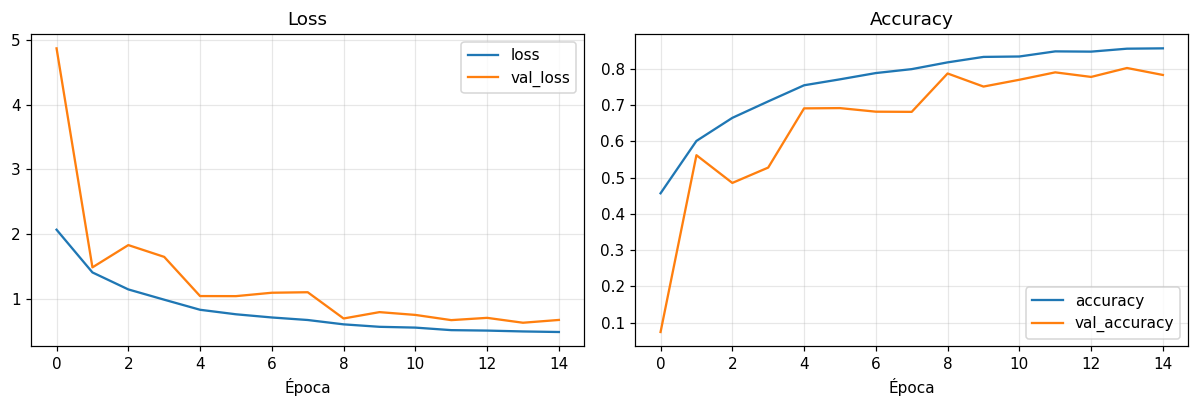

In [9]:
hist = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="Loss")
hist[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Evaluación en test

El conjunto de test se usa solo para medir el rendimiento, no para tomar decisiones de entrenamiento. Se reportan:

- **Accuracy:** proporción de imágenes bien clasificadas.
- **F1 macro:** promedio del F1 de cada clase, dándoles el mismo peso a todas; es la métrica principal por el desbalance entre clases.
- **F1 macro sin la clase fondo:** el mismo promedio sin contar `Background_without_leaves`, para verificar que esa clase no infle el resultado.

Después se muestran la tabla de precision, recall y F1 por clase (de peor a mejor) y el gráfico de F1 por clase.

In [10]:
probs = model.predict(X_test, batch_size=64, verbose=0)
y_pred = probs.argmax(axis=1)

acc = float((y_pred == y_test).mean())
f1_macro = f1_score(y_test, y_pred, average="macro")
labels_no_bg = [c for c in range(n_classes) if c != bg_id]
f1_macro_no_bg = f1_score(y_test, y_pred, labels=labels_no_bg, average="macro")

print(f"Accuracy:                     {acc:.4f}")
print(f"F1 macro:                     {f1_macro:.4f}")
print(f"F1 macro (sin clase fondo):   {f1_macro_no_bg:.4f}")

Accuracy:                     0.8033
F1 macro:                     0.7458
F1 macro (sin clase fondo):   0.7426


In [11]:
names = [id2name[i] for i in range(n_classes)]
report = classification_report(
    y_test, y_pred, labels=list(range(n_classes)),
    target_names=names, zero_division=0, output_dict=True,
)
df_rep = pd.DataFrame(report).T.iloc[:n_classes][["precision", "recall", "f1-score", "support"]]
df_rep.sort_values("f1-score").round(3)

,precision,recall,f1-score,support
Tomato___Spider_mites Two-spotted_spider_mite,0.481,0.302,0.371,252.0
Grape___healthy,1.000,0.286,0.444,63.0
Grape___Black_rot,0.581,0.424,0.490,177.0
Potato___Late_blight,0.569,0.493,0.529,150.0
Apple___Cedar_apple_rust,1.000,0.366,0.536,41.0
Tomato___Target_Spot,0.389,0.896,0.542,211.0
Potato___healthy,0.439,0.783,0.562,23.0
Apple___Apple_scab,0.682,0.479,0.562,94.0
Apple___Black_rot,0.408,0.978,0.576,93.0
Tomato___Early_blight,0.512,0.713,0.596,150.0


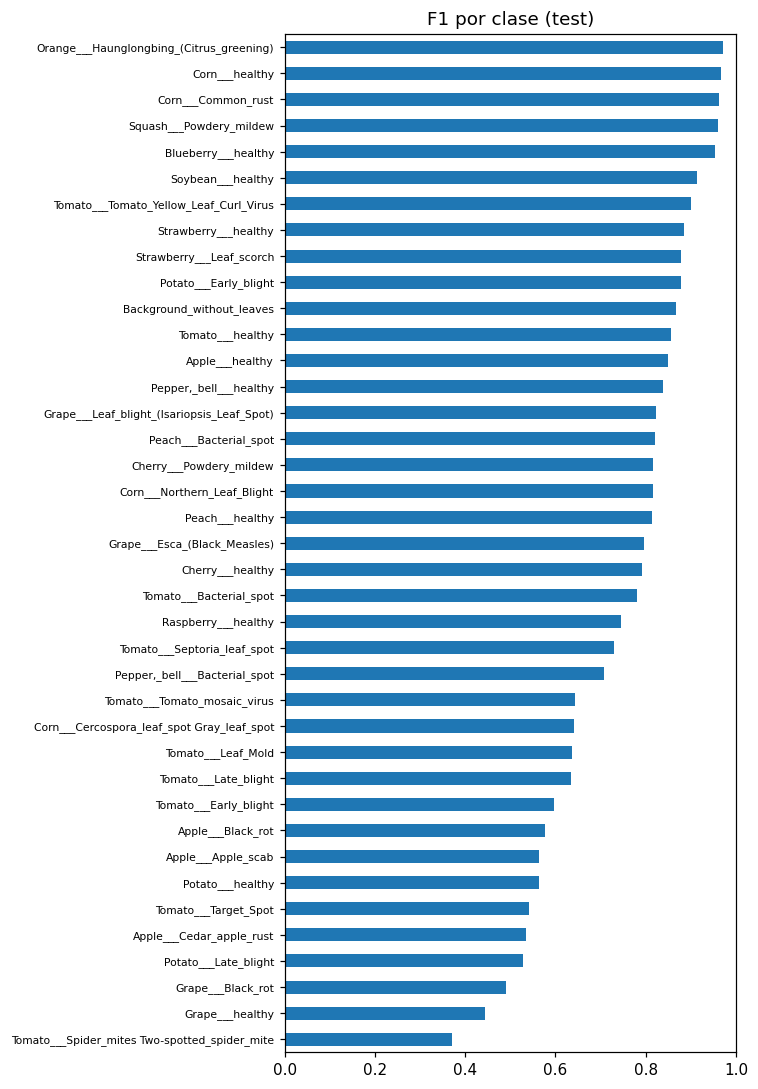

In [12]:
f1_by_class = df_rep["f1-score"].sort_values()
fig, ax = plt.subplots(figsize=(7, 10))
f1_by_class.plot.barh(ax=ax)
ax.set_xlim(0, 1)
ax.set_title("F1 por clase (test)")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### 7.1 Matriz de confusión

Cada fila es la clase real y cada columna la clase predicha, normalizada por fila: la diagonal muestra la proporción de aciertos de cada clase y los valores fuera de la diagonal, los errores. Como son 39 clases, debajo se listan las 10 confusiones más frecuentes.

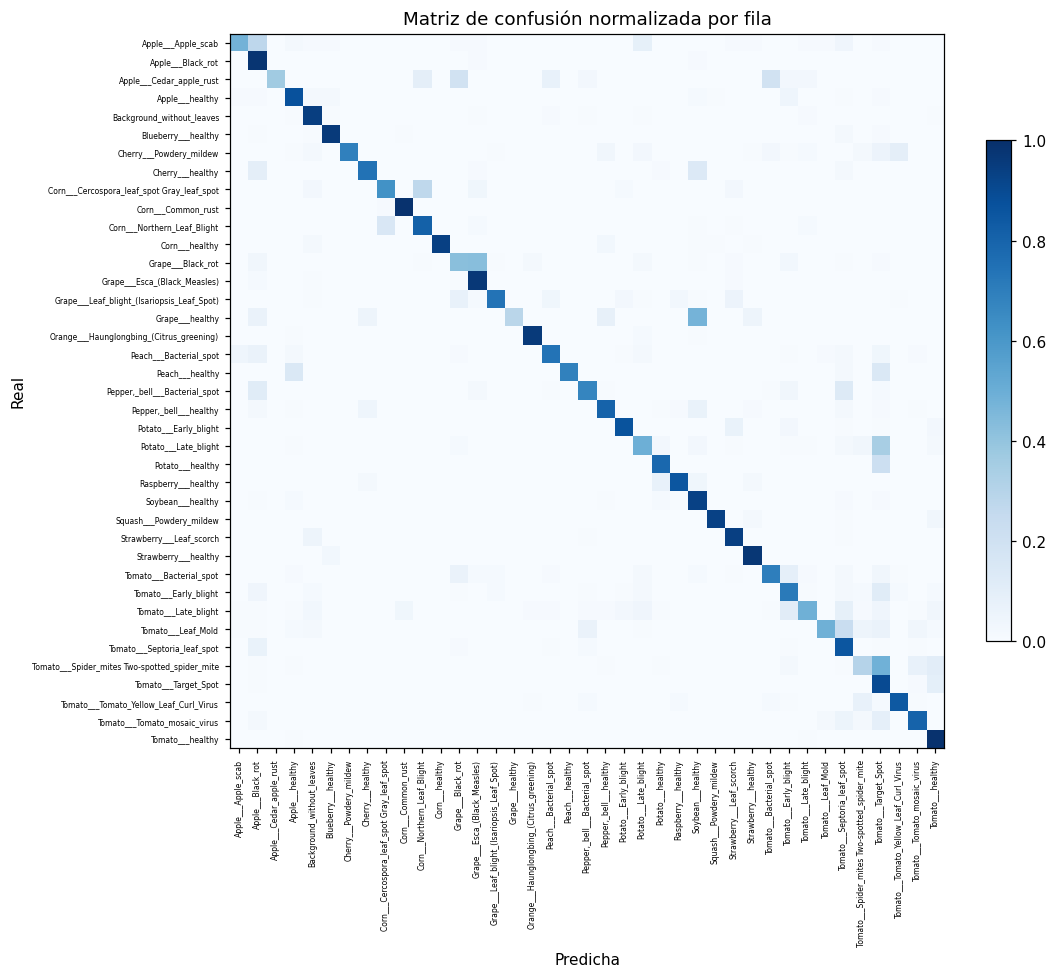

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(n_classes)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xticklabels(names, rotation=90, fontsize=5)
ax.set_yticklabels(names, fontsize=5)
ax.set_xlabel("Predicha")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión normalizada por fila")
plt.colorbar(im, fraction=0.03)
plt.tight_layout()
plt.show()

In [14]:
# Las confusiones más frecuentes (fuera de la diagonal)
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(off[i, j], names[i], names[j]) for i in range(n_classes) for j in range(n_classes) if off[i, j] > 0]
pairs.sort(reverse=True)

pd.DataFrame(pairs[:10], columns=["cantidad", "clase real", "predicha como"])

,cantidad,clase real,predicha como
0,123,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot
1,76,Grape___Black_rot,Grape___Esca_(Black_Measles)
2,61,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Spider_mites Two-spotted_spider_mite
3,51,Potato___Late_blight,Tomato___Target_Spot
4,33,Tomato___Leaf_Mold,Tomato___Septoria_leaf_spot
5,32,Tomato___Late_blight,Tomato___Early_blight
6,30,Grape___healthy,Soybean___healthy
7,28,Tomato___Bacterial_spot,Tomato___Early_blight
8,26,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___healthy
9,26,Apple___Apple_scab,Apple___Black_rot


## 8. Guardar resultados

Los resultados del experimento se guardan en un archivo `.json` dentro de `reports/`, con el nombre del experimento. La tabla final reúne los experimentos de entrenamiento guardados (los de este notebook y los del notebook 03) para compararlos.

In [15]:
results = {
    "experimento": EXP_NAME,
    "img_size": list(IMG_SIZE),
    "subset": USE_SUBSET,
    "class_weight": USE_CLASS_WEIGHT,
    "epocas_corridas": int(len(hist)),
    "minutos_entrenamiento": round(train_time / 60, 1),
    "accuracy": round(acc, 4),
    "f1_macro": round(float(f1_macro), 4),
    "f1_macro_sin_fondo": round(float(f1_macro_no_bg), 4),
    "params": int(model.count_params()),
}
out = os.path.join(ROOT, "reports", f"{EXP_NAME}.json")
with open(out, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Guardado en", out)
results

Guardado en c:\Users\Carlos\Desktop\Python-Prep\proyecto_vision_plantvillage\reports\baseline_nocw_128_subset.json


{'experimento': 'baseline_nocw_128_subset',
 'img_size': [128, 128],
 'subset': True,
 'class_weight': False,
 'epocas_corridas': 15,
 'minutos_entrenamiento': 17.9,
 'accuracy': 0.8033,
 'f1_macro': 0.7458,
 'f1_macro_sin_fondo': 0.7426,
 'params': 103191}

In [16]:
# Tabla comparativa de los experimentos de entrenamiento guardados en reports/
rows = []
for fn in sorted(os.listdir(os.path.join(ROOT, "reports"))):
    if fn.endswith(".json"):
        with open(os.path.join(ROOT, "reports", fn), encoding="utf-8") as f:
            r = json.load(f)
        if "experimento" in r:  # se omiten otros reportes, como el de robustez
            rows.append(r)
pd.DataFrame(rows).set_index("experimento")

,img_size,subset,class_weight,epocas_corridas,minutos_entrenamiento,accuracy,f1_macro,f1_macro_sin_fondo,params
experimento,,,,,,,,,
baseline_cw_128_subset,"[128, 128]",True,True,15,20.0,0.7580,0.7232,0.7233,103191
baseline_nocw_128_subset,"[128, 128]",True,False,15,17.9,0.8033,0.7458,0.7426,103191
tl_mobilenetv3small_224_cw0.0_full,"[224, 224]",False,False,27,0.3,0.9847,0.9800,0.9796,158888
tl_mobilenetv3small_224_cw0.0_subset,"[224, 224]",True,False,27,0.1,0.9675,0.9587,0.9579,158888
tl_mobilenetv3small_224_cw0.5_full,"[224, 224]",False,True,40,0.5,0.9870,0.9818,0.9815,158888
tl_mobilenetv3small_224_cw0.5_subset,"[224, 224]",True,True,32,0.2,0.9681,0.9598,0.9592,158888


## 9. Conclusiones del baseline

- **Rendimiento:** la CNN de 103.191 parámetros, entrenada en CPU con el 25 % de train (9.703 imágenes) y a 128x128, alcanzó accuracy 0,803 y F1 macro 0,746 en test (0,743 sin contar la clase fondo, por lo que esa clase no infla el resultado). El entrenamiento tardó unos 18 minutos.
- **Con vs. sin `class_weight`:** los pesos balanceados no mejoraron el agregado (accuracy 0,758, F1 macro 0,723). Aumentaron el recall de clases chicas, pero a costa de precision: por ejemplo, `Potato___healthy` pasó a recall 1,0 con precision 0,143. Se conserva la versión sin pesos como referencia. Cada configuración se corrió una sola vez, por lo que diferencias pequeñas pueden estar dentro del ruido entre corridas.
- **Curvas de entrenamiento:** no hay sobreajuste marcado. En la última época la accuracy de train es 0,856 y la de validación 0,783 (en la época 14, la de menor `val_loss`, la validación llegó a 0,802). La `val_loss` bajó de forma irregular, de 4,87 en la época 1 a un mínimo de 0,634 en la época 14, y `EarlyStopping` no se activó: el modelo completó las 15 épocas. Esto sugiere que el rendimiento está limitado por el tamaño del modelo y por los datos usados, más que por memorización.
- **Clases más difíciles:** `Tomato___Spider_mites` (F1 0,37), `Grape___healthy` (0,44), `Grape___Black_rot` (0,49), `Potato___Late_blight` (0,53) y `Apple___Cedar_apple_rust` (0,54). La clase `Tomato___Target_Spot` actúa como comodín: recall 0,90 pero precision 0,39.
- **Confusiones frecuentes:** ácaros → `Target_Spot` (123 casos), `Grape___Black_rot` → `Esca` (76) y `Potato___Late_blight` → `Target_Spot` (51). Hay errores entre enfermedades parecidas del mismo cultivo y también entre cultivos distintos, lo que sugiere que el modelo aún no capta bien los rasgos propios de cada cultivo.
- **Limitaciones:** split estratificado sin agrupar por hoja (posible optimismo en las métricas), entrenamiento con un subconjunto y resolución reducida (se pueden perder manchas finas), y una sola corrida por configuración.
- **Próximo paso:** transfer learning con un backbone preentrenado (notebook 03), que usa el mismo subconjunto de train para que la comparación sea justa.